In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

In [2]:
# Baixar os recursos necessários do NLTK
nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\kimlima\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimlima\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [3]:
# Carregar os dados originais
df_nomes = pd.read_csv('nomes_pessoais.csv')
df_nomes['y'] = 1

df_palavras = pd.read_csv('palavras_comuns.csv').sample(n=102561, random_state=42)
df_palavras['y'] = 0

df = pd.concat([df_nomes, df_palavras])
df.shape

(205122, 2)

In [4]:
# Carregar o arquivo gabarito_formatado.csv
unique_words_df = pd.read_csv('gabarito_formatado.csv')

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

# Converter todos os valores '-1' para '0' na coluna 'y'
unique_words_df['y'] = unique_words_df['y'].replace(-1, 0)

words_with_negative_label = unique_words_df[unique_words_df['y'] == -1]

words_with_negative_label_list = words_with_negative_label['palavra'].tolist()

print(words_with_negative_label_list)

# Separar palavras e nomes
words_df = unique_words_df[unique_words_df['y'] == 0]
names_df = unique_words_df[unique_words_df['y'] == 1]

# Samplear aleatoriamente 743 palavras
words_sample_df = words_df.sample(n=743, random_state=42)

# Concatenar as palavras sampleadas com todos os nomes
balanced_test_df = pd.concat([words_sample_df, names_df])

# Shuffle o dataframe para misturar as palavras e os nomes
balanced_test_df = balanced_test_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Verificar a distribuição de rótulos no conjunto de teste balanceado
label_distribution = balanced_test_df['y'].value_counts()
print("Distribuição de rótulos no conjunto de teste balanceado:")
print(label_distribution)

[]
Distribuição de rótulos no conjunto de teste balanceado:
y
1    743
0    743
Name: count, dtype: int64


In [5]:
# Usar o alfabeto e bigrams
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]

vectorizer = CountVectorizer(analyzer='char', vocabulary=alfabeto_bigrams, lowercase=False, ngram_range=(2, 2))

In [6]:
# Vetorizar os dados de treino completos
X_train_vector = vectorizer.fit_transform(df['X'])
y_train = df['y']

# Vetorizar as palavras únicas para teste
X_unique_words_vector = vectorizer.transform(balanced_test_df['palavra'])
y_true = balanced_test_df['y']


RandomForest - Accuracy: 0.8674293405114402, Precision: 0.8592105263157894, Recall: 0.8788694481830417, F1 Score: 0.8689288090485695
              precision    recall  f1-score   support

           0       0.88      0.86      0.87       743
           1       0.86      0.88      0.87       743

    accuracy                           0.87      1486
   macro avg       0.87      0.87      0.87      1486
weighted avg       0.87      0.87      0.87      1486



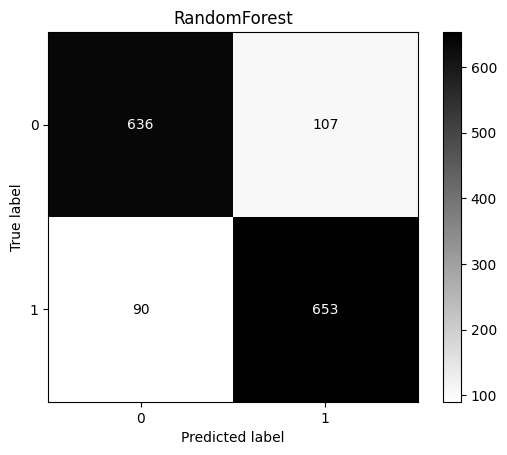

          Model  Accuracy  Precision    Recall  F1 Score  False Negatives
0  RandomForest  0.867429   0.859211  0.878869  0.868929               90

Falsos Negativos para RandomForest:
['PALHETA', 'BESSA', 'FREIRE', 'FURTADO', 'CAMPELO', 'FRAGOSO', 'FESTA', 'PEDTROVICH', 'PASSOS', 'CORREA', 'SAMPAIO', 'TOLDO', 'COLARES', 'TUJI', 'ROBISPIERRE', 'JS', 'CHAVES', 'BARRETO', 'RODRIGUES', 'PUCAR', 'NEGRAO', 'COUNAGO', 'MEDEIROS', 'VAVA', 'O.J', 'KYRIACOPOULOS', 'FONSECA', 'FILHO', 'VICTORGRATIDAOO', 'HOBBIES', 'PARENTES', 'MACHADO', 'GUERREIRO', 'GRATIDAO', 'MAIA', 'TELES', 'CARNEIRO', 'PAIXAO', 'PIMHO', 'DANTAS', 'COTTINI', 'COUTINHO', 'CAVALCANTI', 'AROUCHE', 'MORAIS', 'DELGADO', 'BOMBONATO', 'MIA', 'ARANHA', 'RAMPIN', 'PICANCO', 'CUNHA', 'BENTES', 'BRAGANCA', 'SALES', 'CUTRIM', 'BEZERRA', 'TOURINHO', 'MASCARENHAS', 'VENTUROTI', 'SANTOS', 'DIAMANTE', 'CASTRO', 'CAMPOS', 'PEREIRARENATA', 'CARRATO', 'PENTEADO', 'GONCACVES', 'SANTO', 'PEREIRA', 'BARRA', 'CARMO', 'BEZERROS', 'PIO', 'COELHO', '

In [7]:
# Treinar os modelos
classifiers = {
    # 'SVC': SVC(),
    'RandomForest': RandomForestClassifier(),
    # 'GradientBoosting': GradientBoostingClassifier(),
    # 'LogisticRegression': LogisticRegression()
}

# Dicionário para armazenar as métricas
metrics = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    '    [++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++]': []
}

# Dicionário para armazenar os falsos negativos
false_negatives = {}

for model_name, classifier in classifiers.items():
    classifier.fit(X_train_vector, y_train)
    y_pred = classifier.predict(X_unique_words_vector)

    # Calcular as métricas
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_true, y_pred)
    fn = cm[1, 0]  # Falsos Negativos

    # Adicionar as métricas ao dicionário
    metrics['Model'].append(model_name)
    metrics['Accuracy'].append(accuracy)
    metrics['Precision'].append(precision)
    metrics['Recall'].append(recall)
    metrics['F1 Score'].append(f1)
    metrics['False Negatives'].append(fn)

    # Encontrar os falsos negativos
    fn_indices = [i for i, (true, pred) in enumerate(zip(y_true, y_pred)) if true == 1 and pred == 0]
    false_negatives[model_name] = balanced_test_df.iloc[fn_indices]['palavra'].tolist()

    # Imprimir o relatório de classificação
    report = classification_report(y_true, y_pred)
    print(f"{model_name} - Accuracy: {accuracy}, Precision: {precision}, Recall: {recall}, F1 Score: {f1}")
    print(report)

    # Gerar a matriz de confusão
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap='binary')
    plt.title(model_name)
    plt.show()

# Criar o dataframe com as métricas
metrics_df = pd.DataFrame(metrics)
print(metrics_df)

# Exibir os falsos negativos para cada modelo
for model_name, fn_list in false_negatives.items():
    print(f"\nFalsos Negativos para {model_name}:")
    print(fn_list)

In [9]:
from sklearn.pipeline import Pipeline
from joblib import dump, load

pipeline = Pipeline([
    ('vectorizer', vectorizer),
    ('classifier', classifiers['RandomForest'])
])

dump(pipeline, 'classificador_nomes_att.joblib', compress=True)

['classificador_nomes_att.joblib']